# Phase 3 — Clustering occupations by numeric attributes

**Pipeline:** O*NET attribute scores (abilities, knowledge, work activities, skills) → StandardScaler → K-Means++ vs. Ward agglomerative

Each row is an occupation, each column one attribute's **importance** score (1–5). 910 occupations × 161 attributes.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "../src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from scipy.cluster.hierarchy import linkage, dendrogram
from numeric_clustering import *
pd.set_option("display.max_colwidth", 140)

F_im, F_lv = load_features("IM"), load_features("LV")
occ = pd.read_csv(PROCESSED / "occupations.csv", index_col="code")
interests = pd.read_csv(PROCESSED / "interests.csv", index_col="code")
titles = occ.loc[F_im.index, "title"]
reference = {"SOC": pd.Series(F_im.index.str[:2]),
             "RIASEC": interests.reindex(F_im.index)["top_interest"].fillna("NA").reset_index(drop=True)}
F_im.shape

(910, 161)

## 1. Which scale? Importance (IM) vs. Level (LV)
Each attribute has two scores. If they carry the same information, using both just double-counts.

In [2]:
r = np.corrcoef(F_im.values.ravel(), F_lv.values.ravel())[0, 1]
print(f"Correlation between IM and LV scores: {r:.3f}")

Correlation between IM and LV scores: 0.959


They are almost the same (r ≈ 0.96), so we use **importance only**.

## 2. Standardize
Attributes are on similar 1–5 scales but with very different spreads (e.g. *Oral Comprehension* is important for
almost every job; *Programming* for few). Z-scoring stops high-variance attributes from dominating the distances.

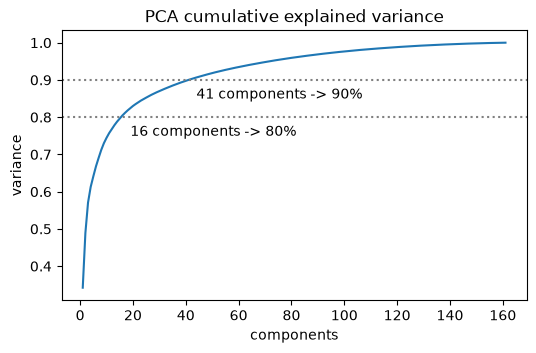

First component alone: 34%


In [3]:
Z = standardize(F_im)

pca = PCA().fit(Z)
cum = pca.explained_variance_ratio_.cumsum()
plt.figure(figsize=(6, 3.5))
plt.plot(range(1, len(cum) + 1), cum)
for t in (0.8, 0.9):
    n = (cum < t).sum() + 1
    plt.axhline(t, ls=":", c="grey"); plt.text(n + 3, t - 0.05, f"{n} components -> {t:.0%}")
plt.title("PCA cumulative explained variance"); plt.xlabel("components"); plt.ylabel("variance"); plt.show()
print(f"First component alone: {cum[0]:.0%}")

The first principal component explains ~34% on its own: roughly a **physical ↔ cognitive/office** axis.
The rest of the variance is spread thinly, which means the job space is a **continuum**, not well-separated islands.

## 3. Choosing K: elbow + silhouette

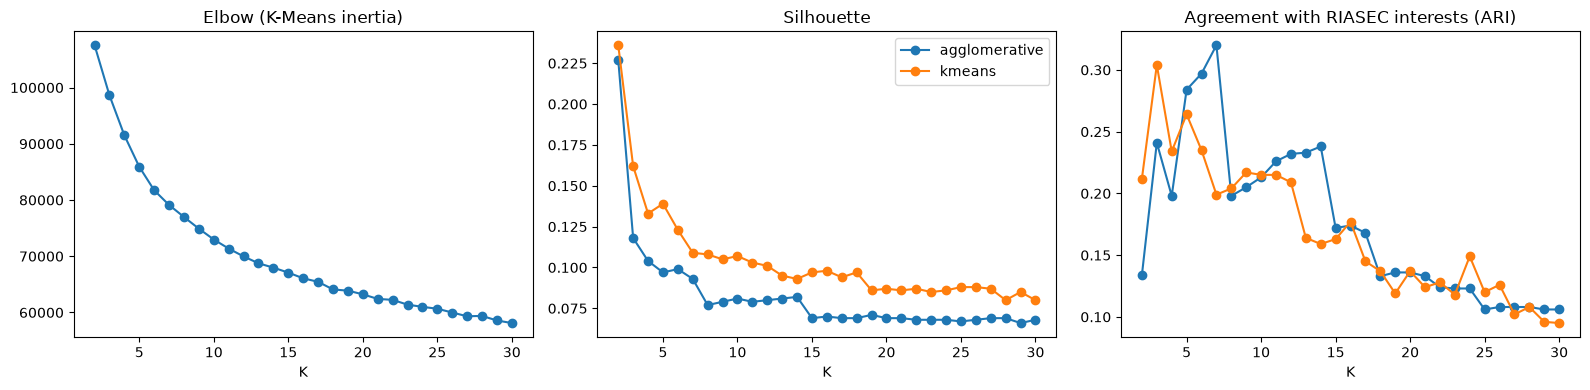

In [4]:
results = sweep(Z, ks=range(2, 31), reference=reference)
km_res = results[results.method == "kmeans"]

fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].plot(km_res.k, km_res.inertia, "o-"); ax[0].set(title="Elbow (K-Means inertia)", xlabel="K")
for m, g in results.groupby("method"):
    ax[1].plot(g.k, g.silhouette, "o-", label=m)
    ax[2].plot(g.k, g.ARI_vs_RIASEC, "o-", label=m)
ax[1].set(title="Silhouette", xlabel="K"); ax[2].set(title="Agreement with RIASEC interests (ARI)", xlabel="K")
ax[1].legend(); plt.tight_layout(); plt.show()

In [5]:
results[results.k.isin([2, 3, 4, 5, 6, 8, 10, 15, 20, 30])].round(3)

,method,k,inertia,n_clusters,noise_pct,silhouette,ARI_vs_SOC,ARI_vs_RIASEC
0,kmeans,2,107528.239,2,0.0,0.236,0.080,0.212
1,agglomerative,2,NaN,2,0.0,0.227,0.073,0.134
2,kmeans,3,98605.921,3,0.0,0.162,0.127,0.304
3,agglomerative,3,NaN,3,0.0,0.118,0.110,0.241
4,kmeans,4,91495.956,4,0.0,0.133,0.149,0.234
5,agglomerative,4,NaN,4,0.0,0.104,0.118,0.198
6,kmeans,5,85901.508,5,0.0,0.139,0.192,0.264
7,agglomerative,5,NaN,5,0.0,0.097,0.160,0.284
8,kmeans,6,81735.598,6,0.0,0.123,0.186,0.235
9,agglomerative,6,NaN,6,0.0,0.099,0.180,0.297


**Observations**
- Silhouette scores are **low (~0.07–0.24)** for every K: the numeric space has no sharp cluster boundaries.
  The math "optimum" is K=2 (physical vs. non-physical jobs), which is too coarse to be useful.
- The elbow is smooth, with no clear bend.
- K-Means beats Ward agglomerative on silhouette at almost every K.
- Agreement with **RIASEC interests peaks around K=3–6** (ARI ≈ 0.23–0.30), much higher than the text clusters (~0.10).

Since the metrics don't single out a K, we choose by **interpretability**: **K=6** gives broad, nameable groups.

## 4. Agglomerative (Ward) dendrogram

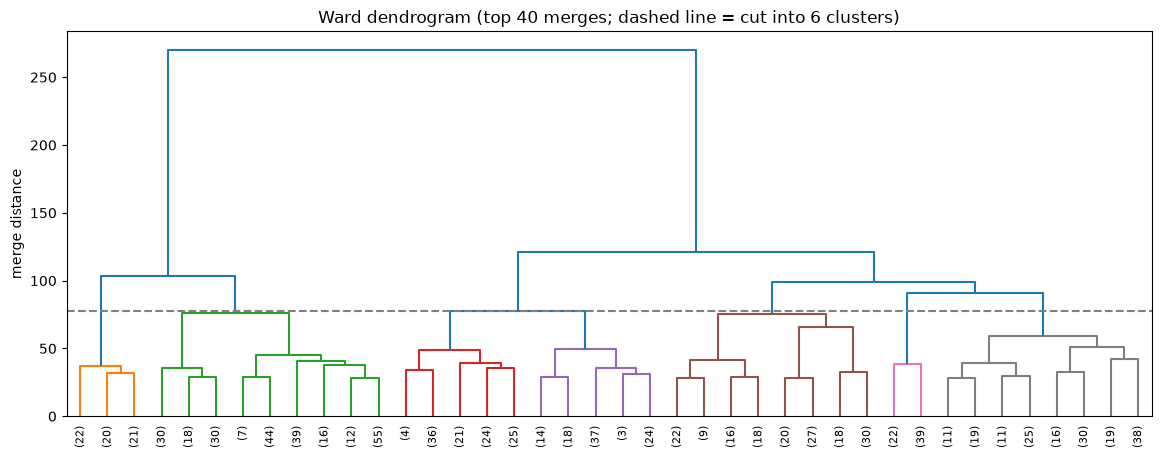

In [6]:
Lk = linkage(Z, method="ward")
plt.figure(figsize=(14, 5))
dendrogram(Lk, truncate_mode="lastp", p=40, leaf_rotation=90, color_threshold=Lk[-6, 2])
plt.axhline(Lk[-6, 2], ls="--", c="grey")
plt.title("Ward dendrogram (top 40 merges; dashed line = cut into 6 clusters)"); plt.ylabel("merge distance"); plt.show()

The tree is the main advantage of agglomerative clustering: it gives a **ready-made hierarchy**, which is
what the nested bubble UI needs. Cutting higher or lower gives coarser or finer levels.

## 5. The K=6 clusters: what defines them?

In [7]:
K = 6
km = run_kmeans(Z, K)
labels = km.labels_
ria = interests.reindex(F_im.index)["top_interest"]

summary = pd.DataFrame({
    "size": pd.Series(labels).value_counts().sort_index(),
    "defining_attributes": profile(Z, labels, n=5),
    "top_interest": [ria[labels == c].value_counts().index[0] for c in range(K)],
    "examples": [", ".join(titles[labels == c].sample(4, random_state=0)) for c in range(K)],
})
summary

,size,defining_attributes,top_interest,examples
0,137,"Programming, Mathematical Reasoning, Mathematics, Technology Design, Engineering and Technology",Investigative,"Software Quality Assurance Analysts and Testers, Environmental Compliance Inspectors, Aerospace Engineering and Operations Technologists..."
1,201,"Equipment Maintenance, Repairing, Repairing and Maintaining Mechanical Equipment, Reaction Time, Operation and Control",Realistic,"Farmworkers, Farm, Ranch, and Aquacultural Animals, Stone Cutters and Carvers, Manufacturing, Riggers, Electrical Power-Line Installers ..."
2,163,"Sociology and Anthropology, Learning Strategies, Speech Clarity, Speaking, Instructing",Social,"Advertising Sales Agents, Pediatricians, General, Rehabilitation Counselors, Fundraising Managers"
3,164,"Assisting and Caring for Others, Medicine and Dentistry, Psychology, Therapy and Counseling, Biology",Realistic,"Agricultural Inspectors, Psychiatric Technicians, Dental Assistants, Hydroelectric Production Managers"
4,122,"Trunk Strength, Stamina, Static Strength, Extent Flexibility, Handling and Moving Objects",Realistic,"Forging Machine Setters, Operators, and Tenders, Metal and Plastic, Textile Knitting and Weaving Machine Setters, Operators, and Tenders..."
5,123,"Administrative, Performing Administrative Activities, Customer and Personal Service, Performing for or Working Directly with the Public,...",Conventional,"Bill and Account Collectors, File Clerks, Appraisers and Assessors of Real Estate, Insurance Sales Agents"


The **defining attributes** (highest average z-score) work as an automatic label, much like TF-IDF on text:

| Cluster theme | Defining attributes |
|---|---|
| Tech & analysis | Programming, Mathematics, Technology Design |
| Mechanical & repair | Equipment Maintenance, Repairing, Operation and Control |
| Teaching & social | Learning Strategies, Speaking, Instructing |
| Healthcare & caregiving | Assisting and Caring for Others, Medicine, Psychology |
| Physical labor | Trunk Strength, Stamina, Handling and Moving Objects |
| Business & admin | Administrative, Customer Service, Sales and Marketing |

(Cluster numbers are arbitrary; match them using the table above.)

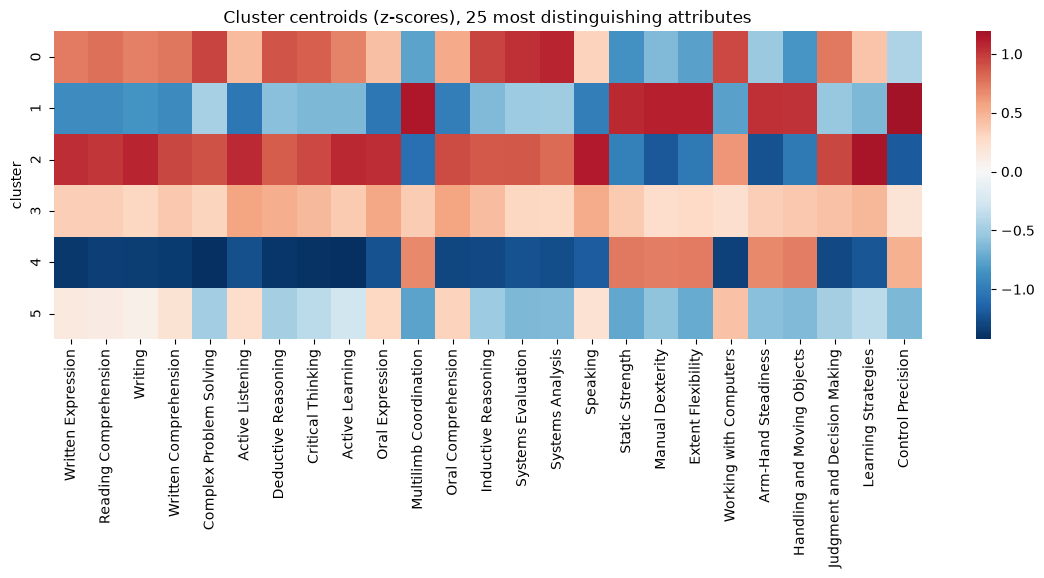

In [8]:
# Heatmap of cluster centroids on the attributes that vary most between clusters
centroids = Z.groupby(labels).mean()
top_attrs = centroids.std().sort_values(ascending=False).index[:25]
plt.figure(figsize=(14, 4))
sns.heatmap(centroids[top_attrs].rename(columns=lambda c: c.split(":", 1)[1]), cmap="RdBu_r", center=0)
plt.title("Cluster centroids (z-scores), 25 most distinguishing attributes"); plt.ylabel("cluster"); plt.show()

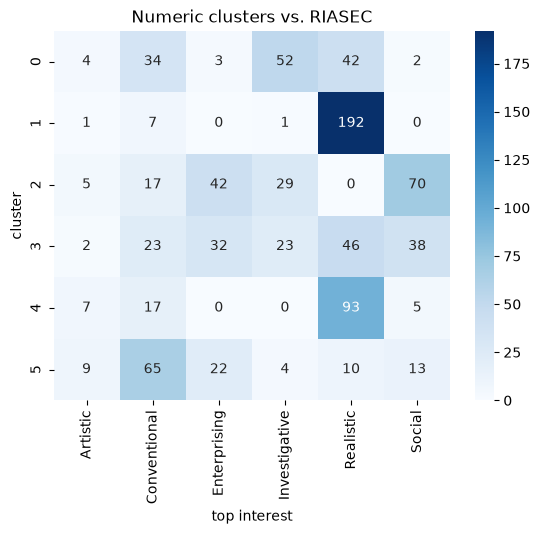

In [9]:
# Clusters vs. RIASEC interest type
ct = pd.crosstab(pd.Series(labels, index=F_im.index, name="cluster"), ria.rename("top interest"))
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues"); plt.title("Numeric clusters vs. RIASEC"); plt.show()

## 6. Niche jobs (silhouette threshold)
K-Means puts every job in a cluster. Jobs with a **negative silhouette** are closer to another cluster than their own:
they don't fit well anywhere. These are flagged as niche, as the README suggests.

In [10]:
niche = misfits(Z, labels, threshold=0.0)
print(f"{niche.sum()} of {len(niche)} jobs ({niche.mean():.0%}) have negative silhouette")
titles[niche].sample(15, random_state=1).tolist()

38 of 910 jobs (4%) have negative silhouette


['Meeting, Convention, and Event Planners',
 'Loading and Moving Machine Operators, Underground Mining',
 'Surveyors',
 'Pesticide Handlers, Sprayers, and Applicators, Vegetation',
 'Desktop Publishers',
 'Tile and Stone Setters',
 'Pest Control Workers',
 'Etchers and Engravers',
 'Clinical Nurse Specialists',
 'Securities, Commodities, and Financial Services Sales Agents',
 'Refractory Materials Repairers, Except Brickmasons',
 'Low Vision Therapists, Orientation and Mobility Specialists, and Vision Rehabilitation Therapists',
 'Fence Erectors',
 'Medical Appliance Technicians',
 'Meat, Poultry, and Fish Cutters and Trimmers']

## 7. 2D view

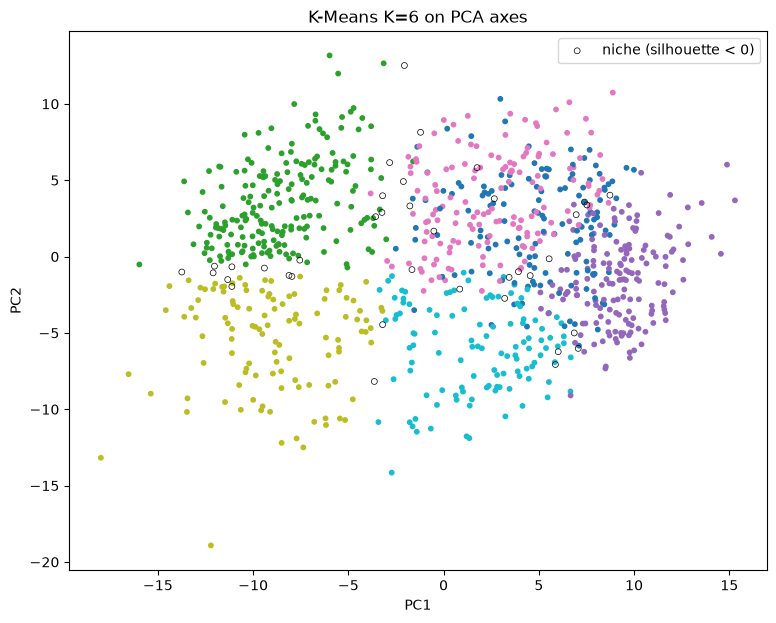

In [11]:
P2 = PCA(n_components=2).fit_transform(Z)
plt.figure(figsize=(9, 7))
plt.scatter(P2[~niche, 0], P2[~niche, 1], c=labels[~niche], cmap="tab10", s=10)
plt.scatter(P2[niche, 0], P2[niche, 1], facecolors="none", edgecolors="k", s=18, lw=0.5, label="niche (silhouette < 0)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.legend(); plt.title(f"K-Means K={K} on PCA axes"); plt.show()

## 8. Comparison with the text clusters (Project 1)
Uses `data/processed/text_clusters.csv` from Project 1's notebook; skipped if that file isn't present.

In [12]:
km30 = run_kmeans(Z, 30).labels_  # also saved at the end of the notebook
text_path = PROCESSED / "text_clusters.csv"
if not text_path.exists():
    print("Skipped: run Project 1 (notebooks/02_text_clustering.ipynb) first to compare with the text clusters.")
else:
    text = pd.read_csv(text_path, index_col="code").loc[F_im.index]
    lab = pd.Series(labels, index=F_im.index)
    print("ARI numeric K=6  vs text K-Means K=30:", round(adjusted_rand_score(lab, text.kmeans), 3))
    print("ARI numeric K=30 vs text K-Means K=30:", round(adjusted_rand_score(km30, text.kmeans), 3))

    # How do the text clusters spread across the 6 numeric groups?
    mask = text.hdbscan.values != -1
    ct = pd.crosstab(text.hdbscan[mask], lab[mask])
    purity = ct.max(axis=1) / ct.sum(axis=1)
    print(f"On average, {purity.mean():.0%} of a text cluster's jobs fall in the same numeric group")

ARI numeric K=6  vs text K-Means K=30: 0.109
ARI numeric K=30 vs text K-Means K=30: 0.233
On average, 63% of a text cluster's jobs fall in the same numeric group


## 9. Findings

| | Text clusters (Phase 2) | Numeric clusters (Phase 3) |
|---|---|---|
| What they capture | **what** the job is about (field / domain) | **how** the job is done (physical, social, analytical…) |
| Cluster separation | clear (silhouette ~0.60 after UMAP) | weak (silhouette ~0.07–0.24), a continuum |
| Best granularity | fine (~30 clusters) | broad (~6 clusters) |
| Matches RIASEC interests | poorly (ARI ~0.10) | better (ARI ~0.23–0.30) |

- The README expected numeric data to cluster "remarkably well". In practice it doesn't separate cleanly,
  because jobs change gradually from physical to cognitive work. The clusters are still **meaningful and easy to name**.
- K-Means++ beats Ward agglomerative on silhouette, but Ward gives a **tree**, which helps build the hierarchy.
- The two approaches capture **different things** and agree only partly (low ARI), so they complement each other.

**Recommendation for the bubble UI (Phase 5):**
- **Level 1 (broad):** numeric K=6 groups such as "Helping & caring", "Building & fixing", "Tech & analysis".
  These line up with interests like "I want to help people".
- **Level 2 (detailed):** text-based subclusters *computed inside each Level 1 group*, which capture the field.
  The global text clusters can't be reused as-is: on average only 63% of a text cluster's jobs land in the same
  numeric group (e.g. a "healthcare" text cluster spans both the caregiving and the tech/analysis groups).
- **Level 3:** individual occupations, with niche jobs marked.

In [13]:
out = pd.DataFrame({"title": titles, "kmeans6": labels, "kmeans30": km30,
                    "agglo6": run_agglomerative(Z, 6), "niche": niche,
                    "pca_x": P2[:, 0], "pca_y": P2[:, 1]}, index=F_im.index)
out.to_csv(PROCESSED / "numeric_clusters.csv")
summary[["size", "defining_attributes", "top_interest"]].to_csv(PROCESSED / "numeric_cluster_profiles.csv")
out.head()

,title,kmeans6,kmeans30,agglo6,niche,pca_x,pca_y
code,,,,,,,
11-1011.00,Chief Executives,2,3,4,False,14.877012,6.020195
11-1011.03,Chief Sustainability Officers,2,3,2,False,11.759110,1.372922
11-1021.00,General and Operations Managers,2,3,4,False,7.881747,1.505883
11-2011.00,Advertising and Promotions Managers,2,3,4,False,9.235859,-1.532468
11-2021.00,Marketing Managers,2,3,4,False,10.408225,-0.090452
